In [6]:
import pandas as pd
import matplotlib . pyplot as plt
import seaborn as sns

df = pd.read_csv('Fahrraddiebstahl.csv', sep=',', encoding='latin1')
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 32794 entries, 0 to 32793
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   ANGELEGT_AM            32794 non-null  str  
 1   TATZEIT_ANFANG_DATUM   32794 non-null  str  
 2   TATZEIT_ANFANG_STUNDE  32794 non-null  int64
 3   TATZEIT_ENDE_DATUM     32794 non-null  str  
 4   TATZEIT_ENDE_STUNDE    32794 non-null  int64
 5   LOR                    32794 non-null  int64
 6   SCHADENSHOEHE          32794 non-null  int64
 7   VERSUCH                32794 non-null  str  
 8   ART_DES_FAHRRADS       32794 non-null  str  
 9   DELIKT                 32794 non-null  str  
 10  ERFASSUNGSGRUND        32794 non-null  str  
dtypes: int64(4), str(7)
memory usage: 2.8 MB
None


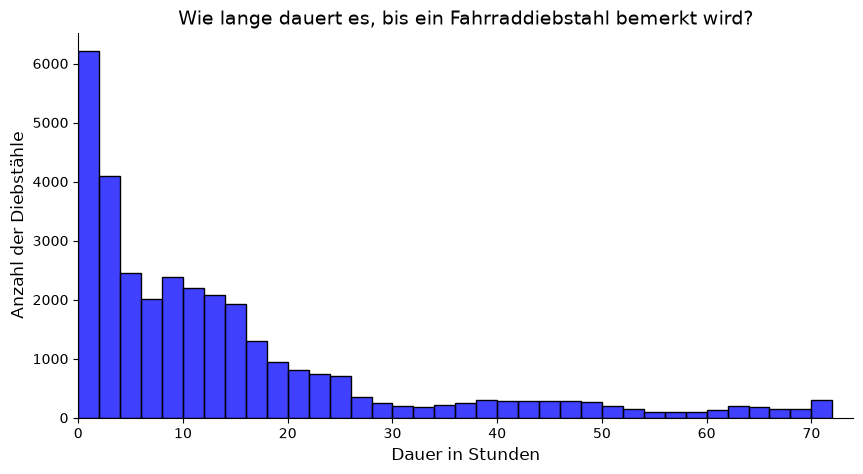

In [10]:
# Datum und Uhrzeit kombinieren
# Datum: 'TT.MM.JJJJ', Stunde: Zahl
df['Start_Zeit'] = pd.to_datetime(df['TATZEIT_ANFANG_DATUM'], format='%d.%m.%Y') + pd.to_timedelta(df['TATZEIT_ANFANG_STUNDE'], unit='h')
df['Ende_Zeit'] = pd.to_datetime(df['TATZEIT_ENDE_DATUM'], format='%d.%m.%Y') + pd.to_timedelta(df['TATZEIT_ENDE_STUNDE'], unit='h')

# Wie viele Stunden lagen zwischen Start und Ende?
df['Tatdauer_Stunden'] = (df['Ende_Zeit'] - df['Start_Zeit']).dt.total_seconds() / 3600

# Wochentag extrahieren
df['Wochentag'] = df['Start_Zeit'].dt.day_name()

# Zeitfenster zwischen Tatbeginn und Tatende (bis 72 Std.; Tatzeitfenster)
# Tatzeitende = Besitzer stellt fest, dass sein Fahrrad weg ist. Tatzeitbeginn = Zeitpunkt, an dem das Fahrrad zuletzt gesehen wurde.
# Immer 2er Schritte: 0-2 Std., 2-4 Std., 4-6 Std., ...
fig, ax = plt.subplots(figsize=(10, 5))
ax = sns.histplot(data=df, x='Tatdauer_Stunden', bins=36, color='blue', edgecolor='black')

# 1. Lücke links entfernen (x-Achse startet exakt bei 0)
ax.set_xlim(0, 74)

ax.set_title('Wie lange dauert es, bis ein Fahrraddiebstahl bemerkt wird?', fontsize=14)
ax.set_xlabel('Dauer in Stunden', fontsize=12)
ax.set_ylabel('Anzahl der Diebstähle', fontsize=12)
sns.despine()
plt.show()

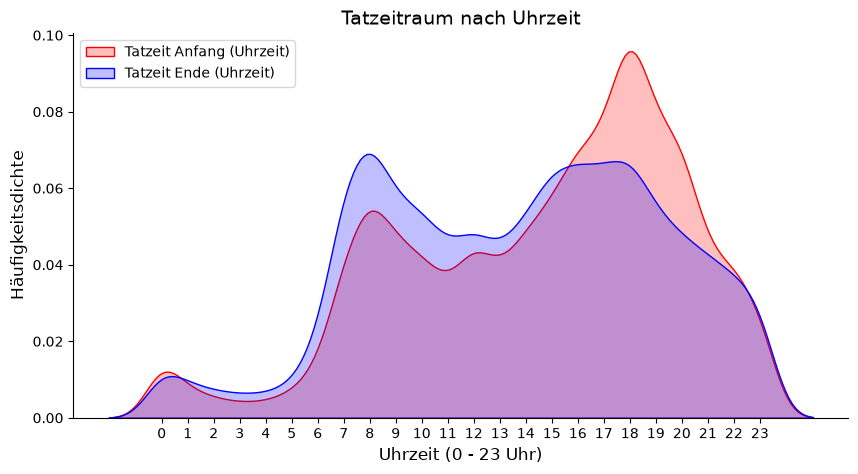

In [11]:
#Wann wird geklaut? (Vergleich Start- vs. End-Uhrzeit)
fix, ax = plt.subplots(figsize=(10, 5))

sns.kdeplot(df['TATZEIT_ANFANG_STUNDE'], label='Tatzeit Anfang (Uhrzeit)', fill=True, color='red')
sns.kdeplot(df['TATZEIT_ENDE_STUNDE'], label='Tatzeit Ende (Uhrzeit)', fill=True, color='blue')

ax.set_title('Tatzeitraum nach Uhrzeit', fontsize=14)
ax.set_xlabel('Uhrzeit (0 - 23 Uhr)', fontsize=12)
ax.set_ylabel('Häufigkeitsdichte', fontsize=12)
ax.set_xticks(range(0, 24))
ax.legend()
sns.despine()
plt.show()

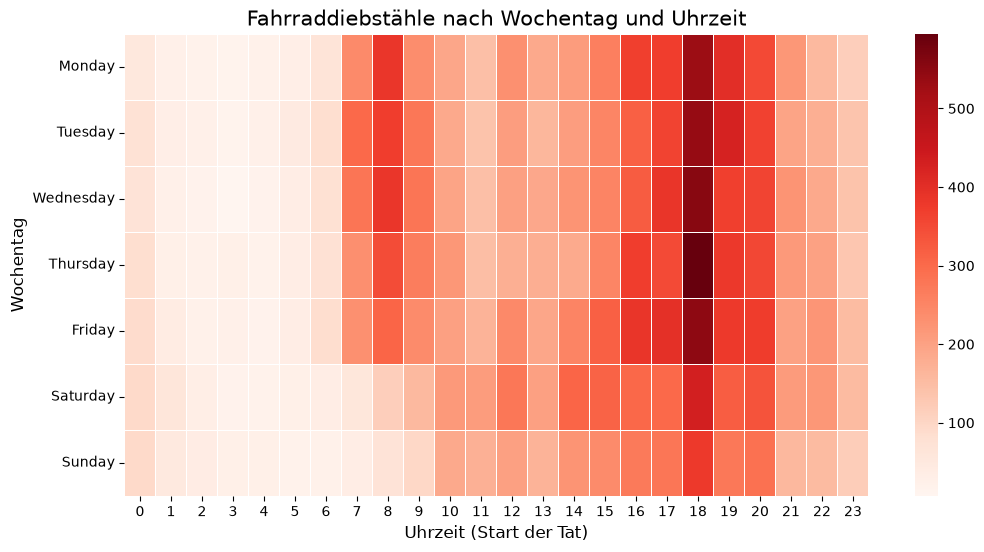

In [25]:
# Heatmap: Wochentag vs. Start-Stunde
# Wochentage müssen auf Englisch sein, sonst werden die Daten nicht gefunden
reihenfolge = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_daten = pd.crosstab(df['Wochentag'], df['TATZEIT_ANFANG_STUNDE']).reindex(reihenfolge)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(heatmap_daten, cmap='Reds', linewidths=0.5)

ax.set_title('Fahrraddiebstähle nach Wochentag und Uhrzeit', fontsize=15)
ax.set_xlabel('Uhrzeit (Start der Tat)', fontsize=12)
ax.set_ylabel('Wochentag', fontsize=12)
plt.show()

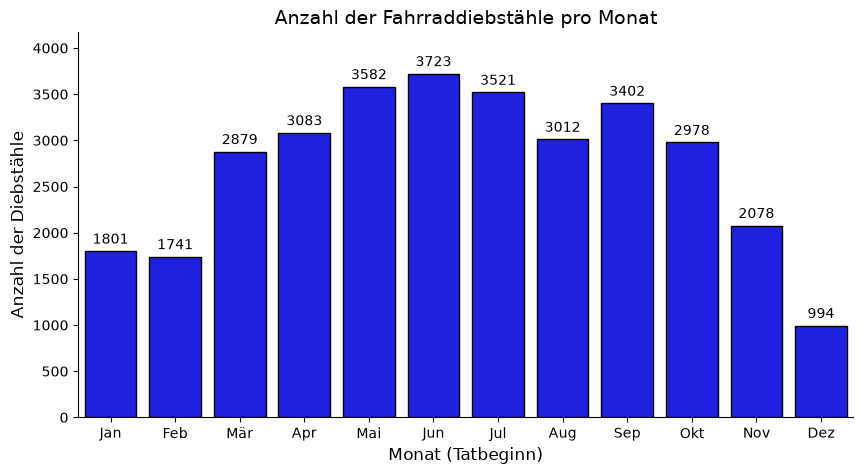

In [18]:
# In welchem Monat wird am meisten geklaut? (Vergleich Start- vs. End-Monat)
# Monat (1 = Januar, 12 = Dezember)
df['Monat_Nr'] = df['Start_Zeit'].dt.month

# Fälle pro Monat + Monate in richtiger Reihenfolge
monats_daten = df['Monat_Nr'].value_counts().reindex(range(1, 13), fill_value=0)

# Zahlen durch deutsche Monatsnamen ersetzen
monate_de = ['Jan', 'Feb', 'Mär', 'Apr', 'Mai', 'Jun', 'Jul', 'Aug', 'Sep', 'Okt', 'Nov', 'Dez']
monats_daten.index = monate_de

# 4. Balkendiagramm zeichnen
fig, ax = plt.subplots(figsize=(10, 5))
ax = sns.barplot(x=monats_daten.index, y=monats_daten.values, color='blue', edgecolor='black')

# Fallzahlen direkt über jedem Balken
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

ax.set_title('Anzahl der Fahrraddiebstähle pro Monat', fontsize=14)
ax.set_xlabel('Monat (Tatbeginn)', fontsize=12)
ax.set_ylabel('Anzahl der Diebstähle', fontsize=12)
ax.set_ylim(0, monats_daten.max() * 1.12)

sns.despine()
plt.show()